In [5]:
# Ajuste e avaliação usam o mesmo ensaio; as métricas são exploratórias, sem teste independente.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from IPython.display import display


PASTA = Path(
    "../resultados/ensaio_20261014_194020"
)

features = pd.read_csv(
    PASTA / "features.csv"
)

avaliacao = pd.read_csv(
    PASTA / "avaliacao.csv"
)


dataset_simples = features.merge(
    avaliacao,
    on="janela",
    validate="one_to_one"
)


print(
    "Total de janelas:",
    len(dataset_simples)
)

display(
    dataset_simples.head()
)

Total de janelas: 140


,janela,ts_inicio,duracao_s,taxa_requisicoes,bytes_rx,bytes_tx,latencia_ms,taxa_timeout,taxa_erro,consultas_cliente,latencia_disponivel,label,fase
0,0,1.792018e+09,1.0,1.0,12,13,1.4412,0.0,0.0,1,1,0,normal
1,1,1.792018e+09,1.0,1.0,12,13,1.9333,0.0,0.0,1,1,0,normal
2,2,1.792018e+09,1.0,1.0,12,13,1.2996,0.0,0.0,1,1,0,normal
3,3,1.792018e+09,1.0,1.0,12,13,1.3890,0.0,0.0,1,1,0,normal
4,4,1.792018e+09,1.0,1.0,12,13,2.1055,0.0,0.0,1,1,0,normal


In [6]:
display(
    dataset_simples[
        "fase"
    ].value_counts()
)

display(
    dataset_simples[
        "label"
    ].value_counts()
)

fase
normal         60
recuperacao    59
carga          21
Name: count, dtype: int64

label
0    119
1     21
Name: count, dtype: int64

In [7]:
COLUNAS_ML = [
    "taxa_requisicoes",
    "latencia_ms",
    "latencia_disponivel"
]

X = dataset_simples[
    COLUNAS_ML
].copy()

display(
    pd.DataFrame({
        "ausentes": X.isna().sum(),
        "distintos": X.nunique(),
        "minimo": X.min(),
        "maximo": X.max()
    })
)

,ausentes,distintos,minimo,maximo
taxa_requisicoes,0,5,1.000,52.0000
latencia_ms,0,140,1.057,11.1877
latencia_disponivel,0,1,1.000,1.0000


In [8]:
COLUNAS_CONTINUAS = [
    "taxa_requisicoes",
    "latencia_ms"
]

scaler = StandardScaler()

X_normalizado = X.copy()

X_normalizado[
    COLUNAS_CONTINUAS
] = scaler.fit_transform(
    X[
        COLUNAS_CONTINUAS
    ]
)

display(
    X_normalizado.describe().round(3)
)

,taxa_requisicoes,latencia_ms,latencia_disponivel
count,140.000,140.000,140.0
mean,-0.000,-0.000,1.0
std,1.004,1.004,0.0
min,-0.409,-1.046,1.0
25%,-0.409,-0.390,1.0
50%,-0.409,-0.103,1.0
75%,-0.409,0.181,1.0
max,2.509,10.542,1.0


In [9]:
resultados_k = []

for k in range(2, 11):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    clusters = modelo.fit_predict(
        X_normalizado
    )

    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(
            X_normalizado,
            clusters
        )
    })


resultado_k = pd.DataFrame(
    resultados_k
)

display(
    resultado_k.round(4)
)

,k,inercia,silhouette
0,2,136.2273,0.8171
1,3,26.4181,0.8266
2,4,12.6860,0.5821
3,5,7.3581,0.6241
4,6,4.6081,0.5959
5,7,3.5221,0.5371
6,8,2.7432,0.5261
7,9,1.9748,0.5456
8,10,1.5192,0.5428


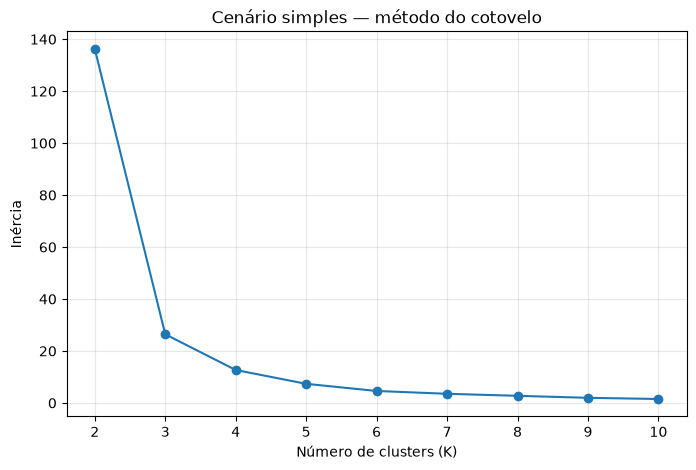

In [10]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    resultado_k["k"],
    resultado_k["inercia"],
    marker="o"
)

ax.set_title(
    "Cenário simples — método do cotovelo"
)

ax.set_xlabel(
    "Número de clusters (K)"
)

ax.set_ylabel(
    "Inércia"
)

ax.grid(alpha=0.3)

plt.show()

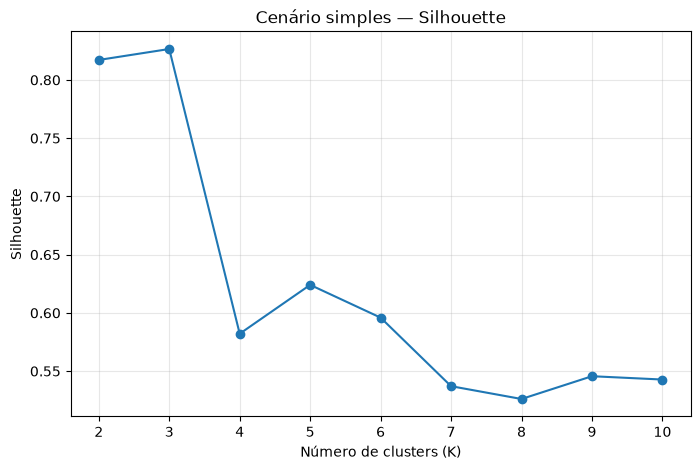

In [11]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    resultado_k["k"],
    resultado_k["silhouette"],
    marker="o"
)

ax.set_title(
    "Cenário simples — Silhouette"
)

ax.set_xlabel(
    "Número de clusters (K)"
)

ax.set_ylabel(
    "Silhouette"
)

ax.grid(alpha=0.3)

plt.show()

In [12]:
K_SIMPLES = 3

kmeans_simples = KMeans(
    n_clusters=K_SIMPLES,
    random_state=42,
    n_init=20
)

clusters_simples = (
    kmeans_simples.fit_predict(
        X_normalizado
    )
)

print(
    "Clusters:",
    sorted(set(clusters_simples))
)

Clusters: [np.int32(0), np.int32(1), np.int32(2)]


In [13]:
contagem = (
    pd.Series(
        clusters_simples
    )
    .value_counts()
    .sort_index()
)

display(
    contagem.rename(
        "quantidade"
    )
)

0    119
1     20
2      1
Name: quantidade, dtype: int64

In [14]:
display(
    (
        contagem
        / len(clusters_simples)
        * 100
    )
    .round(2)
    .rename("percentual")
)

0    85.00
1    14.29
2     0.71
Name: percentual, dtype: float64

In [15]:
centroides_normalizados = pd.DataFrame(
    kmeans_simples.cluster_centers_,
    columns=COLUNAS_ML
)

centroides_normalizados.index.name = (
    "cluster"
)

display(
    centroides_normalizados.round(3)
)

,taxa_requisicoes,latencia_ms,latencia_disponivel
cluster,,,
0,-0.408,-0.121,1.0
1,2.449,0.192,1.0
2,-0.409,10.542,1.0


In [16]:
centroides_originais = (
    centroides_normalizados.copy()
)

centroides_originais[
    COLUNAS_CONTINUAS
] = scaler.inverse_transform(
    centroides_normalizados[
        COLUNAS_CONTINUAS
    ]
)

display(
    centroides_originais.round(3)
)

,taxa_requisicoes,latencia_ms,latencia_disponivel
cluster,,,
0,1.008,1.866,1.0
1,50.950,2.139,1.0
2,1.000,11.188,1.0


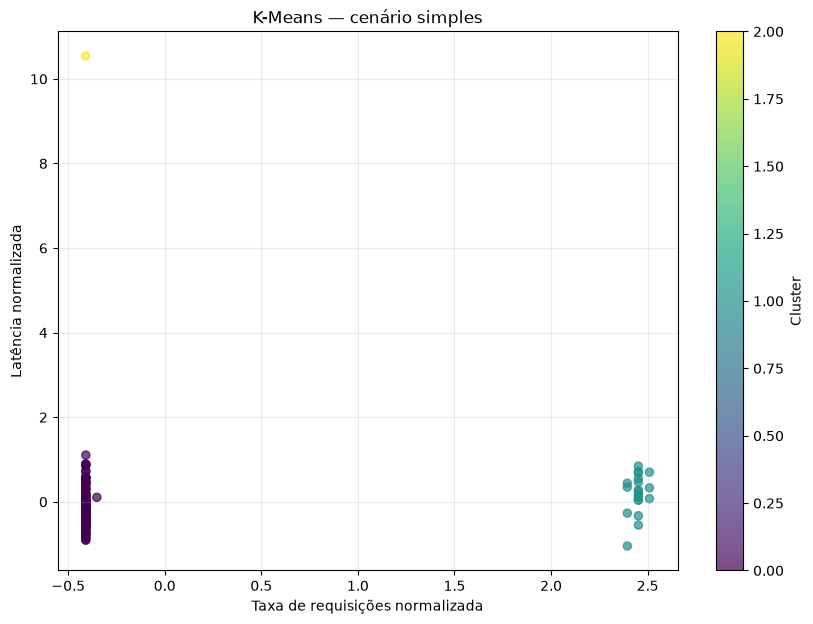

In [17]:
fig, ax = plt.subplots(
    figsize=(10, 7)
)

scatter = ax.scatter(
    X_normalizado[
        "taxa_requisicoes"
    ],
    X_normalizado[
        "latencia_ms"
    ],
    c=clusters_simples,
    s=35,
    alpha=0.7
)

ax.set_title(
    "K-Means — cenário simples"
)

ax.set_xlabel(
    "Taxa de requisições normalizada"
)

ax.set_ylabel(
    "Latência normalizada"
)

plt.colorbar(
    scatter,
    ax=ax,
    label="Cluster"
)

ax.grid(alpha=0.25)

plt.show()

In [18]:
resultado_simples = (
    dataset_simples[
        [
            "janela",
            "label",
            "fase"
        ]
    ]
    .copy()
)

resultado_simples[
    "cluster"
] = clusters_simples

In [19]:
tabela_condicao = pd.crosstab(
    resultado_simples[
        "cluster"
    ],
    resultado_simples[
        "fase"
    ]
)

display(
    tabela_condicao
)

fase,carga,normal,recuperacao
cluster,,,
0,1,59,59
1,20,0,0
2,0,1,0


In [20]:
display(
    (
        pd.crosstab(
            resultado_simples[
                "cluster"
            ],
            resultado_simples[
                "fase"
            ],
            normalize="index"
        ) * 100
    ).round(2)
)

fase,carga,normal,recuperacao
cluster,,,
0,0.84,49.58,49.58
1,100.00,0.00,0.00
2,0.00,100.00,0.00


In [21]:
tabela_label = pd.crosstab(
    resultado_simples[
        "cluster"
    ],
    resultado_simples[
        "label"
    ]
)

display(
    tabela_label
)

label,0,1
cluster,,
0,118,1
1,0,20
2,1,0


In [22]:
percentual_label = (
    pd.crosstab(
        resultado_simples[
            "cluster"
        ],
        resultado_simples[
            "label"
        ],
        normalize="index"
    ) * 100
)

display(
    percentual_label.round(2)
)

label,0,1
cluster,,
0,99.16,0.84
1,0.00,100.00
2,100.00,0.00


In [23]:
proporcao_ataque = (
    resultado_simples
    .groupby(
        "cluster"
    )[
        "label"
    ]
    .mean()
)

display(
    (
        proporcao_ataque * 100
    )
    .round(2)
    .rename(
        "percentual_ataque"
    )
)

cluster
0      0.84
1    100.00
2      0.00
Name: percentual_ataque, dtype: float64

In [24]:
MAPA_KMEANS_SIMPLES = {
    cluster: int(
        proporcao > 0.50
    )

    for cluster, proporcao
    in proporcao_ataque.items()
}

print(
    MAPA_KMEANS_SIMPLES
)

{0: 0, 1: 1, 2: 0}


In [25]:
resultado_simples[
    "previsao"
] = (
    resultado_simples[
        "cluster"
    ]
    .map(
        MAPA_KMEANS_SIMPLES
    )
)

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


y_real = resultado_simples[
    "label"
]

y_previsto = resultado_simples[
    "previsao"
]


print(
    "Acurácia:",
    round(
        accuracy_score(
            y_real,
            y_previsto
        ),
        4
    )
)

print(
    "Precisão:",
    round(
        precision_score(
            y_real,
            y_previsto
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_real,
            y_previsto
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_real,
            y_previsto
        ),
        4
    )
)

Acurácia: 0.9929
Precisão: 1.0
Recall: 0.9524
F1: 0.9756


In [27]:
matriz = confusion_matrix(
    y_real,
    y_previsto
)

display(
    pd.DataFrame(
        matriz,
        index=[
            "Real legítimo",
            "Real ataque"
        ],
        columns=[
            "Previsto legítimo",
            "Previsto ataque"
        ]
    )
)

,Previsto legítimo,Previsto ataque
Real legítimo,119,0
Real ataque,1,20
